# Лабораторна 7. Завдання 1 — автоматична валідація (пункти 1–13)

Набір **Horses vs Humans**: до базового ноутбука додано другий, **валідаційний** набір даних
і другий генератор, а в `model.fit` — параметри `validation_data` і `validation_steps`.
Модель і параметри навчання не змінювалися: вхід 300×300, `RMSprop(learning_rate=0.001)`,
`steps_per_epoch=8`, `epochs=15`.

Визначаємо середовище і шляхи.

In [1]:
# Визначення середовища та базових шляхів (працює і локально, і в Colab)
import json
import os
import time
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

LAB_ROOT = Path("/content") if IN_COLAB else Path.cwd().parent   # notebooks/ -> dl/lab7
DATA = LAB_ROOT / "data"
MY_IMAGES = LAB_ROOT / "my_images"
RESULTS = LAB_ROOT / "results"
MODELS = LAB_ROOT / "models"
for d in (DATA, RESULTS / "raw", MODELS):
    d.mkdir(parents=True, exist_ok=True)
print("IN_COLAB =", IN_COLAB)
print("LAB_ROOT =", LAB_ROOT)

IN_COLAB = False
LAB_ROOT = C:\uni_year_4\dl\lab7


**Пункти 2–3.** Завантажуємо **два** набори: навчальний (`./horse-or-human`) і
валідаційний (`./validation-horse-or-human`) — другий модель під час навчання не бачить.

In [2]:
import urllib.request
import zipfile

URLS = {
    "horse-or-human.zip": "https://storage.googleapis.com/learning-datasets/horse-or-human.zip",
    "validation-horse-or-human.zip": "https://storage.googleapis.com/learning-datasets/validation-horse-or-human.zip",
}
TRAIN_DIR = DATA / "horse-or-human"
VALID_DIR = DATA / "validation-horse-or-human"

for name, url in URLS.items():
    target = TRAIN_DIR if name == "horse-or-human.zip" else VALID_DIR
    zip_path = DATA / name
    if not (target / "horses").is_dir():
        if not zip_path.exists():
            print("Завантаження", name, "...")
            urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(target)
    print(target, "->", sorted(os.listdir(target)))

C:\uni_year_4\dl\lab7\data\horse-or-human -> ['horses', 'humans']
C:\uni_year_4\dl\lab7\data\validation-horse-or-human -> ['horses', 'humans']


**Пункт 4.** Перевірка імен файлів у каталогах навчання і валідації.

In [3]:
train_horse_dir = TRAIN_DIR / "horses"
train_human_dir = TRAIN_DIR / "humans"
validation_horse_dir = VALID_DIR / "horses"
validation_human_dir = VALID_DIR / "humans"

train_horse_names = sorted(os.listdir(train_horse_dir))
train_human_names = sorted(os.listdir(train_human_dir))
validation_horse_names = sorted(os.listdir(validation_horse_dir))
validation_human_names = sorted(os.listdir(validation_human_dir))

print("TRAIN horses:", train_horse_names[:5])
print("TRAIN humans:", train_human_names[:5])
print("VAL   horses:", validation_horse_names[:5])
print("VAL   humans:", validation_human_names[:5])
print("total training horse images:", len(train_horse_names))
print("total training human images:", len(train_human_names))
print("total validation horse images:", len(validation_horse_names))
print("total validation human images:", len(validation_human_names))

TRAIN horses: ['horse01-0.png', 'horse01-1.png', 'horse01-2.png', 'horse01-3.png', 'horse01-4.png']
TRAIN humans: ['human01-00.png', 'human01-01.png', 'human01-02.png', 'human01-03.png', 'human01-04.png']
VAL   horses: ['horse1-000.png', 'horse1-105.png', 'horse1-122.png', 'horse1-127.png', 'horse1-170.png']
VAL   humans: ['valhuman01-00.png', 'valhuman01-01.png', 'valhuman01-02.png', 'valhuman01-03.png', 'valhuman01-04.png']
total training horse images: 500
total training human images: 527
total validation horse images: 128
total validation human images: 128


**Пункт 5.** Перегляд кількох навчальних зображень.

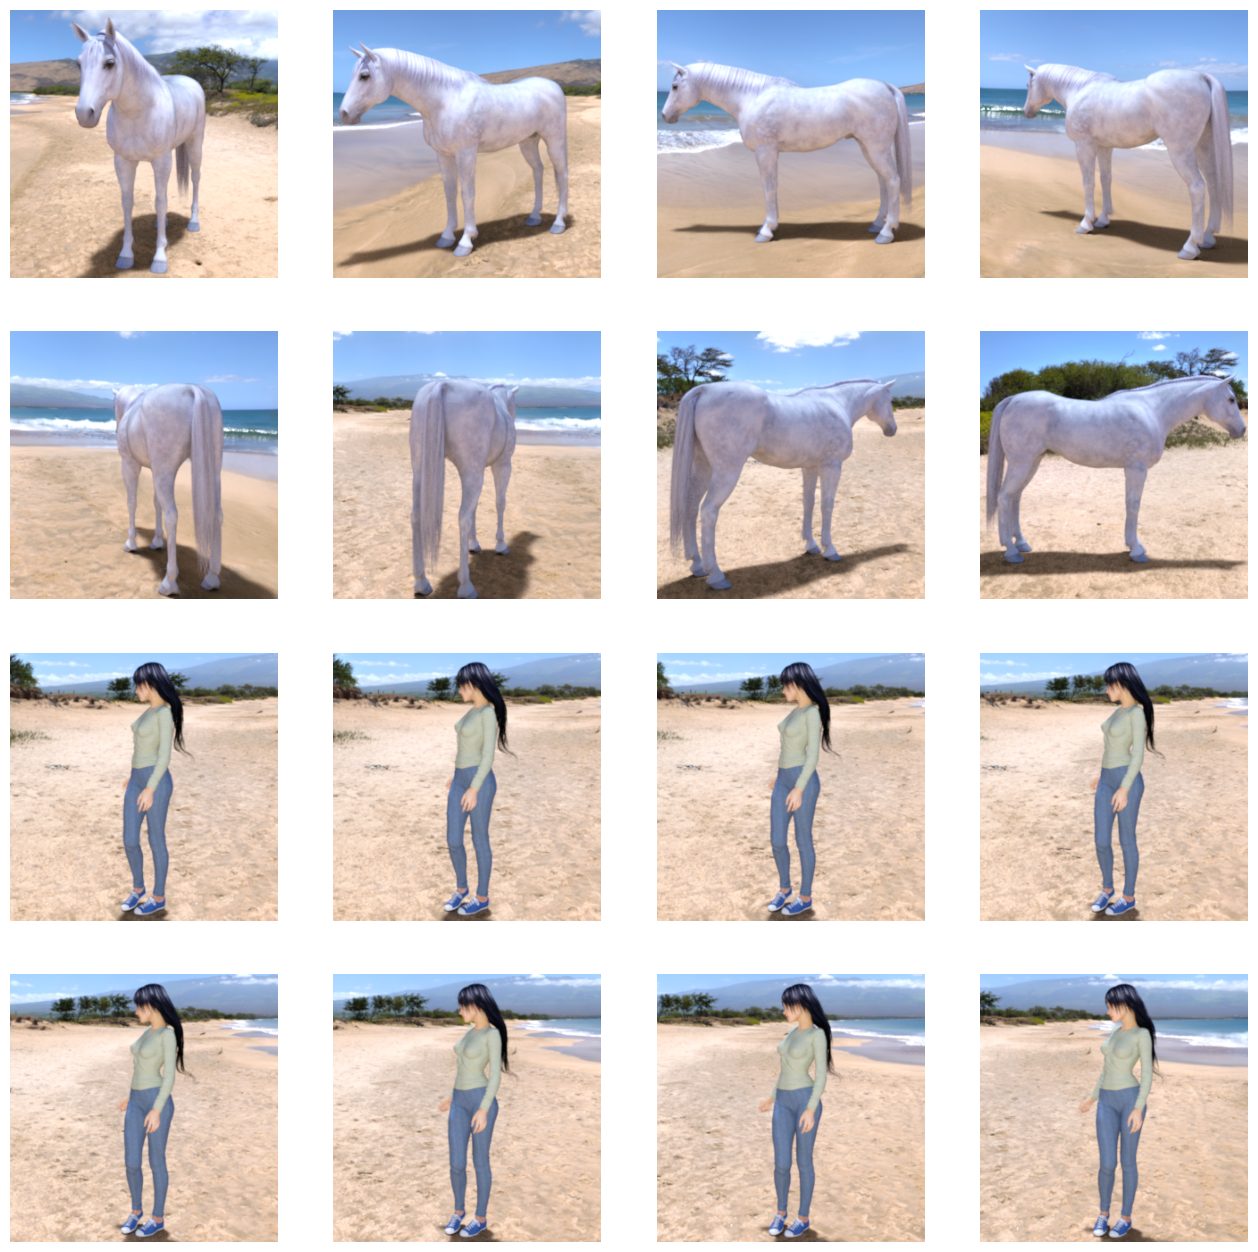

In [4]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

nrows, ncols, pic_index = 4, 4, 8
fig = plt.gcf()
fig.set_size_inches(ncols * 4, nrows * 4)
next_horse_pix = [train_horse_dir / f for f in train_horse_names[pic_index - 8:pic_index]]
next_human_pix = [train_human_dir / f for f in train_human_names[pic_index - 8:pic_index]]
for i, img_path in enumerate(next_horse_pix + next_human_pix):
    sp = plt.subplot(nrows, ncols, i + 1)
    sp.axis("Off")
    plt.imshow(mpimg.imread(img_path))
plt.savefig(RESULTS / "task1_dataset_sample.png", dpi=90, bbox_inches="tight")
plt.show()

**Пункти 6–7.** Модель та її опис — **без змін** порівняно з базовим ноутбуком.
У `summary()` має бути послідовність 298 → 149 → 147 → 73 → 71 → 35 → 33 → 16 → 14 → 7,
Flatten = 7·7·64 = **3136**.

In [5]:
import tensorflow as tf

model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(16, (3, 3), activation="relu", input_shape=(300, 300, 3)),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),   # 0 = horses, 1 = humans
])
model.summary()

C:\uni_year_4\dl\lab7\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 298, 298, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 149, 149, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 147, 147, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 73, 73, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 71, 71, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 35, 35, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 33, 33, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,606,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,704,097 (6.50 MB)

 Trainable params: 1,704,097 (6.50 MB)

 Non-trainable params: 0 (0.00 B)

**Пункт 8.** Компіляція з тими самими параметрами: `binary_crossentropy`, `RMSprop(learning_rate=0.001)`.

In [6]:
from tensorflow.keras.optimizers import RMSprop

model.compile(loss="binary_crossentropy",
              optimizer=RMSprop(learning_rate=0.001),
              metrics=["accuracy"])
summary_lines = []
model.summary(print_fn=lambda s: summary_lines.append(s))
(RESULTS / "raw" / "task1_model_summary.txt").write_text("\n".join(summary_lines), encoding="utf-8")
total_params = int(model.count_params())
print("Усього параметрів:", total_params)

Усього параметрів: 1704097


**Пункт 9.** Два генератори: навчальний і **валідаційний**.
Обидва нормалізують пікселі (`rescale=1/255`), але читають з різних каталогів,
`target_size=(300, 300)`. У виводі має бути `Found 1027 images` і `Found 256 images` —
це доказ, що валідаційний генератор читає саме свій каталог.

In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1 / 255)
validation_datagen = ImageDataGenerator(rescale=1 / 255)

train_generator = train_datagen.flow_from_directory(
    str(TRAIN_DIR),
    target_size=(300, 300),
    batch_size=128,
    class_mode="binary")

validation_generator = validation_datagen.flow_from_directory(
    str(VALID_DIR),
    target_size=(300, 300),
    batch_size=32,
    class_mode="binary")

print("Класи train:", train_generator.class_indices)
print("Класи val:  ", validation_generator.class_indices)

Found 1027 images belonging to 2 classes.


Found 256 images belonging to 2 classes.


Класи train: {'horses': 0, 'humans': 1}
Класи val:   {'horses': 0, 'humans': 1}


**Пункти 10–11.** Навчання з валідацією: додано `validation_data` і `validation_steps=8`.
Наприкінці кожної епохи, крім `loss/accuracy`, друкуються `val_loss/val_accuracy`.

In [8]:
start = time.time()
history = model.fit(
    train_generator,
    steps_per_epoch=8,
    epochs=15,
    verbose=2,
    validation_data=validation_generator,
    validation_steps=8)
train_time = time.time() - start
print(f"Час навчання: {train_time:.1f} с")

Epoch 1/15


8/8 - 22s - 3s/step - accuracy: 0.5495 - loss: 0.8098 - val_accuracy: 0.5000 - val_loss: 0.7157


Epoch 2/15


C:\uni_year_4\dl\lab7\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


8/8 - 3s - 417ms/step - accuracy: 0.5000 - loss: 0.6774 - val_accuracy: 0.5000 - val_loss: 0.7995


...

Epoch 14/15


8/8 - 3s - 427ms/step - accuracy: 0.7422 - loss: 0.4728 - val_accuracy: 0.7539 - val_loss: 0.9207


Epoch 15/15


8/8 - 16s - 2s/step - accuracy: 0.9155 - loss: 0.2408 - val_accuracy: 0.8047 - val_loss: 1.1325


Час навчання: 163.6 с


**Пункт 12.** Графіки історії навчання: точність і втрати на навчальному та валідаційному наборах.

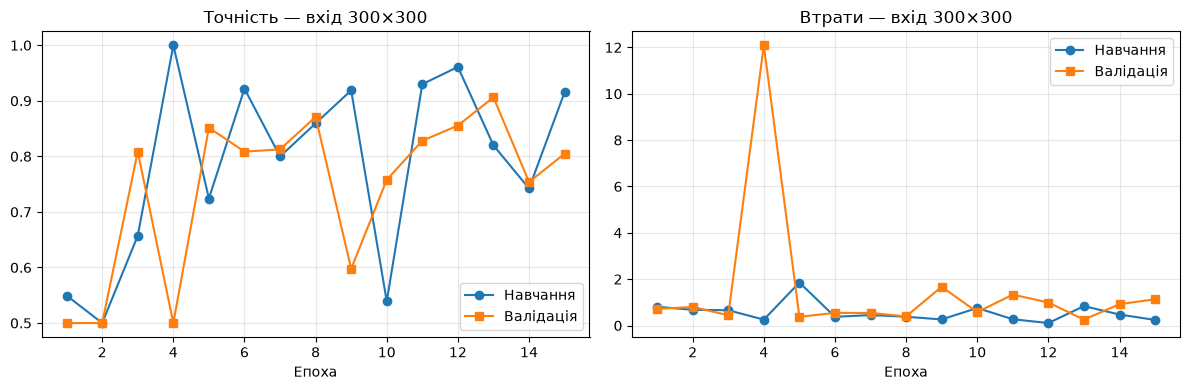

In [9]:
acc_hist = history.history
epochs_range = range(1, len(acc_hist["accuracy"]) + 1)
plt.figure(figsize=(12, 4))
for i, (m, name) in enumerate([("accuracy", "Точність"), ("loss", "Втрати")]):
    plt.subplot(1, 2, i + 1)
    h = acc_hist
    plt.plot(epochs_range, h[m], "o-", label="Навчання")
    plt.plot(epochs_range, h["val_" + m], "s-", label="Валідація")
    plt.title(name + " — вхід 300×300")
    plt.xlabel("Епоха")
    plt.legend()
    plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS / "task1_history.png", dpi=110, bbox_inches="tight")
plt.show()

In [10]:
acc, val_acc = history.history["accuracy"], history.history["val_accuracy"]
loss, val_loss = history.history["loss"], history.history["val_loss"]
print(f"Остання епоха: acc={acc[-1]:.4f}, val_acc={val_acc[-1]:.4f}, "
      f"loss={loss[-1]:.4f}, val_loss={val_loss[-1]:.4f}")
print(f"Найкраща val_accuracy: {max(val_acc):.4f} (епоха {val_acc.index(max(val_acc)) + 1})")
print(f"Розрив train-val на останній епосі: {acc[-1] - val_acc[-1]:+.4f}")

Остання епоха: acc=0.9155, val_acc=0.8047, loss=0.2408, val_loss=1.1325
Найкраща val_accuracy: 0.9062 (епоха 13)
Розрив train-val на останній епосі: +0.1108


**Пункт 13.** Розпізнавання тих самих власних зображень,
що і в базовому ноутбуці. Клас 1 = *humans*, клас 0 = *horses*.

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.utils import img_to_array, load_img


def expected_class(stem):
    """Правильна відповідь береться з префікса імені файлу."""
    if stem.startswith("human"):
        return "human"
    if stem.startswith("horse"):
        return "horse"
    return None          # both_* — на зображенні одночасно людина і кінь


def own_image_paths(folder_name):
    """Локально — з my_images/<folder>, у Colab — через files.upload()."""
    if IN_COLAB:
        from google.colab import files
        target = Path("/content/my_images") / folder_name
        target.mkdir(parents=True, exist_ok=True)
        print("Оберіть власні зображення для завантаження:")
        for fn, data in files.upload().items():
            (target / fn).write_bytes(data)
    else:
        target = MY_IMAGES / folder_name
    return sorted(p for p in target.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})


def predict_images(model, paths, target_size, title, out_png):
    """Передбачення + сітка зображень; повертає рядки для таблиці у звіті."""
    cols = 4
    rows = (len(paths) + cols - 1) // cols
    plt.figure(figsize=(cols * 3.3, rows * 3.7))
    records = []
    for i, p in enumerate(paths):
        img = load_img(p, target_size=target_size)
        x = np.expand_dims(img_to_array(img) / 255.0, axis=0)
        prob = float(model.predict(x, verbose=0)[0][0])
        label = "human" if prob > 0.5 else "horse"
        exp = expected_class(p.stem)
        ok = None if exp is None else (label == exp)
        records.append({"file": p.name, "prob_human": round(prob, 4), "predicted": label,
                        "expected": exp, "correct": ok})
        ax = plt.subplot(rows, cols, i + 1)
        ax.axis("off")
        ax.imshow(load_img(p))
        mark = "" if ok is None else ("  +" if ok else "  -")
        ax.set_title(f"{p.stem[:24]}\n{label}  p={prob:.3f}{mark}", fontsize=8)
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(out_png, dpi=110, bbox_inches="tight")
    plt.show()
    for r in records:
        print(r)
    known = [r for r in records if r["correct"] is not None]
    print(f"\nПравильно: {sum(r['correct'] for r in known)} з {len(known)} "
          f"(файли both_* не враховано)")
    return records

Знайдено зображень: 12


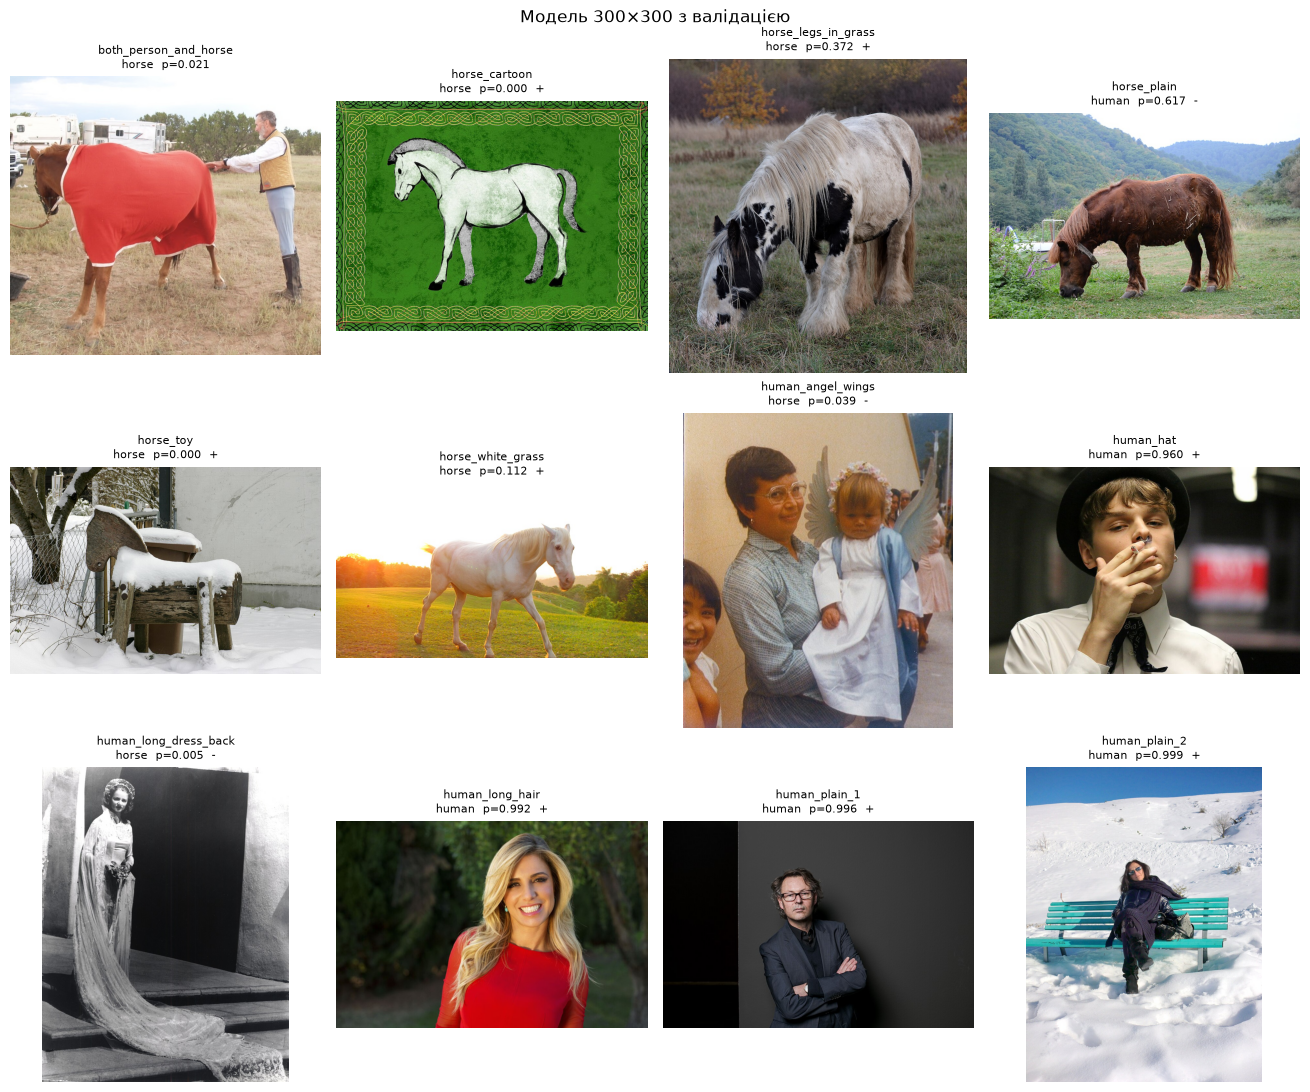

{'file': 'both_person_and_horse.jpg', 'prob_human': 0.0214, 'predicted': 'horse', 'expected': None, 'correct': None}
{'file': 'horse_cartoon.jpg', 'prob_human': 0.0, 'predicted': 'horse', 'expected': 'horse', 'correct': True}
{'file': 'horse_legs_in_grass.jpg', 'prob_human': 0.3717, 'predicted': 'horse', 'expected': 'horse', 'correct': True}
{'file': 'horse_plain.jpg', 'prob_human': 0.617, 'predicted': 'human', 'expected': 'horse', 'correct': False}
{'file': 'horse_toy.jpg', 'prob_human': 0.0001, 'predicted': 'horse', 'expected': 'horse', 'correct': True}
{'file': 'horse_white_grass.jpg', 'prob_human': 0.1116, 'predicted': 'horse', 'expected': 'horse', 'correct': True}
{'file': 'human_angel_wings.jpg', 'prob_human': 0.0391, 'predicted': 'horse', 'expected': 'human', 'correct': False}
{'file': 'human_hat.jpg', 'prob_human': 0.9603, 'predicted': 'human', 'expected': 'human', 'correct': True}
{'file': 'human_long_dress_back.jpg', 'prob_human': 0.0049, 'predicted': 'horse', 'expected': 'hu

In [12]:
paths = own_image_paths("task1_horses_humans")
print("Знайдено зображень:", len(paths))
records = predict_images(model, paths, (300, 300),
                         "Модель 300×300 з валідацією",
                         RESULTS / "task1_predictions.png")

Збереження моделі та чисел для звіту.

In [13]:
model.save(MODELS / "task1_horses_humans_300.keras")
metrics = {
    "task": "task1",
    "input_size": [300, 300],
    "optimizer": "RMSprop(learning_rate=0.001)",
    "steps_per_epoch": 8,
    "validation_steps": 8,
    "epochs_planned": 15,
    "epochs_done": len(history.history["accuracy"]),
    "total_params": total_params,
    "train_time_sec": round(train_time, 1),
    "history": {k: [round(float(v), 4) for v in vals] for k, vals in history.history.items()},
    "train_samples": int(train_generator.samples),
    "validation_samples": int(validation_generator.samples),
    "class_indices": train_generator.class_indices,
    "own_images": records,
}
(RESULTS / "raw" / "task1.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2),
                                                  encoding="utf-8")
print("Збережено results/raw/task1.json")

Збережено results/raw/task1.json
